### 1. Load Data

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

# Load dataset
df = pd.read_csv('elect demand.csv')
print("Columns:", df.columns)
display(df.head())

Columns: Index(['date_1', 'day', 'month', 'year', 'temp2(c)', 'temp2_max(c)',
       'temp2_min(c)', 'temp2_ave(c)', 'suface_pressure(pa)',
       'wind_speed50_max(m/s)', 'wind_speed50_min(m/s)',
       'wind_speed50_ave(m/s)', 'prectotcorr', 'total_demand(mw)', 'date_2',
       'max_generation(mw)'],
      dtype='object')


,date_1,day,month,year,temp2(c),temp2_max(c),temp2_min(c),temp2_ave(c),suface_pressure(pa),wind_speed50_max(m/s),wind_speed50_min(m/s),wind_speed50_ave(m/s),prectotcorr,total_demand(mw),date_2,max_generation(mw)
0,01/01/2018,1,1,2018,19.11,24.48,13.78,19.130,101.08,5.05,0.23,2.640,0.00,8000.0,01/01/2018,7651.0
1,02/01/2018,2,1,2018,18.24,23.16,15.28,19.220,100.94,6.20,1.59,3.895,0.01,7900.0,02/01/2018,7782.0
2,03/01/2018,3,1,2018,15.78,22.65,11.52,17.085,101.12,6.96,3.64,5.300,0.17,7900.0,03/01/2018,7707.0
3,04/01/2018,4,1,2018,13.78,20.32,8.19,14.255,101.34,5.91,1.54,3.725,0.34,8000.0,04/01/2018,7715.0
4,05/01/2018,5,1,2018,13.87,20.79,8.24,14.515,101.17,6.02,3.09,4.555,0.00,7200.0,05/01/2018,6926.0


### 2. Data Preparation

In [13]:
# Convert date columns and extract features
df['date_1'] = pd.to_datetime(df['date_1'], format='%d/%m/%Y', errors='coerce')
df['date_2'] = pd.to_datetime(df['date_2'], format='%d/%m/%Y', errors='coerce')

df['date_1_day'] = df['date_1'].dt.day
df['date_1_month'] = df['date_1'].dt.month
df['date_1_year'] = df['date_1'].dt.year

df['date_2_day'] = df['date_2'].dt.day
df['date_2_month'] = df['date_2'].dt.month
df['date_2_year'] = df['date_2'].dt.year

# Drop original datetime columns
df.drop(['date_1', 'date_2'], axis=1, inplace=True)

# Drop rows where target or features are NaN
df_cleaned = df.dropna()

# Separate features (x) and target variable (y)
x = df_cleaned.drop('total_demand(mw)', axis=1)
y = df_cleaned['total_demand(mw)']

# Split data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=100)

### 3. Linear Regression Model

In [14]:
lr = LinearRegression()
lr.fit(x_train, y_train)

# Predictions
y_lr_train_pred = lr.predict(x_train)
y_lr_test_pred = lr.predict(x_test)

# Evaluation Metrics
lr_train_mse = mean_squared_error(y_train, y_lr_train_pred)
lr_train_r2 = r2_score(y_train, y_lr_train_pred)
lr_test_mse = mean_squared_error(y_test, y_lr_test_pred)
lr_test_r2 = r2_score(y_test, y_lr_test_pred)

lr_results = pd.DataFrame(['Linear regression', lr_train_mse, lr_train_r2, lr_test_mse, lr_test_r2]).transpose()
lr_results.columns = ['Method', 'Training MSE', 'Training R2', 'Testing MSE', 'Testing R2']
display(lr_results)

,Method,Training MSE,Training R2,Testing MSE,Testing R2
0,Linear regression,292897.395862,0.896988,263111.531572,0.901249


### 4. Random Forest Model

In [15]:
rf = RandomForestRegressor(max_depth=2, random_state=100)
rf.fit(x_train, y_train)

# Predictions
y_rf_train_pred = rf.predict(x_train)
y_rf_test_pred = rf.predict(x_test)

# Evaluation Metrics
rf_train_mse = mean_squared_error(y_train, y_rf_train_pred)
rf_train_r2 = r2_score(y_train, y_rf_train_pred)
rf_test_mse = mean_squared_error(y_test, y_rf_test_pred)
rf_test_r2 = r2_score(y_test, y_rf_test_pred)

rf_results = pd.DataFrame(['Random Forest', rf_train_mse, rf_train_r2, rf_test_mse, rf_test_r2]).transpose()
rf_results.columns = ['Method', 'Training MSE', 'Training R2', 'Testing MSE', 'Testing R2']
display(rf_results)

,Method,Training MSE,Training R2,Testing MSE,Testing R2
0,Random Forest,455536.92784,0.839788,427145.79625,0.839683


### 5. XGBoost Model

In [16]:
xgb = XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.08,
                    subsample=0.9, colsample_bytree=0.9, random_state=100)
xgb.fit(x_train, y_train)

# Predictions
y_xgb_train_pred = xgb.predict(x_train)
y_xgb_test_pred = xgb.predict(x_test)

# Evaluation Metrics
xgb_train_mse = mean_squared_error(y_train, y_xgb_train_pred)
xgb_train_r2 = r2_score(y_train, y_xgb_train_pred)
xgb_test_mse = mean_squared_error(y_test, y_xgb_test_pred)
xgb_test_r2 = r2_score(y_test, y_xgb_test_pred)

xgb_results = pd.DataFrame(['XGBoost', xgb_train_mse, xgb_train_r2, xgb_test_mse, xgb_test_r2]).transpose()
xgb_results.columns = ['Method', 'Training MSE', 'Training R2', 'Testing MSE', 'Testing R2']
display(xgb_results)

,Method,Training MSE,Training R2,Testing MSE,Testing R2
0,XGBoost,38321.341264,0.986522,157357.154024,0.940941


### 6. Model Comparison

In [17]:
df_models = pd.concat([lr_results, rf_results, xgb_results], axis=0).reset_index(drop=True)
display(df_models)

,Method,Training MSE,Training R2,Testing MSE,Testing R2
0,Linear regression,292897.395862,0.896988,263111.531572,0.901249
1,Random Forest,455536.92784,0.839788,427145.79625,0.839683
2,XGBoost,38321.341264,0.986522,157357.154024,0.940941


### 7. Data Visualization

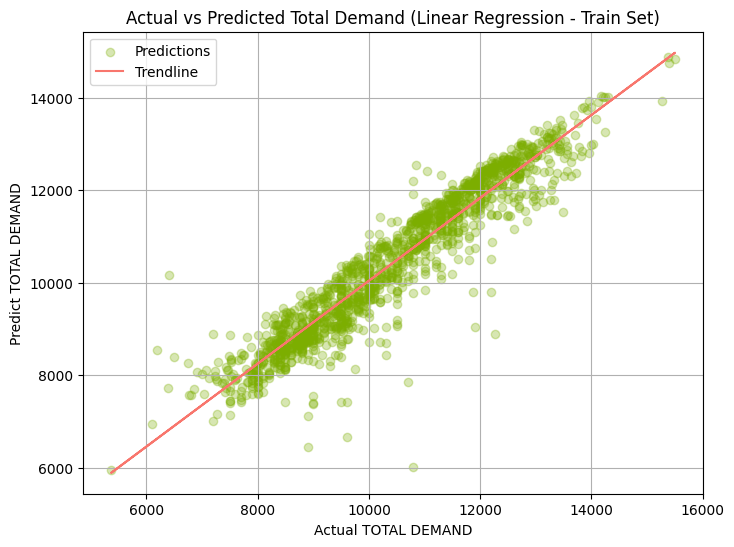

In [18]:
# Plot 1: Actual vs Predicted Scatter plot with trendline (Linear Regression Train Set)
plt.figure(figsize=(8, 6))
plt.scatter(x=y_train, y=y_lr_train_pred, c="#7CAE00", alpha=0.3, label='Predictions')
z = np.polyfit(y_train, y_lr_train_pred, 1)
p = np.poly1d(z)
plt.plot(y_train, p(y_train), '#F8766D', label='Trendline')
plt.ylabel('Predict TOTAL DEMAND')
plt.xlabel('Actual TOTAL DEMAND')
plt.title('Actual vs Predicted Total Demand (Linear Regression - Train Set)')
plt.legend()
plt.grid(True)
plt.show()

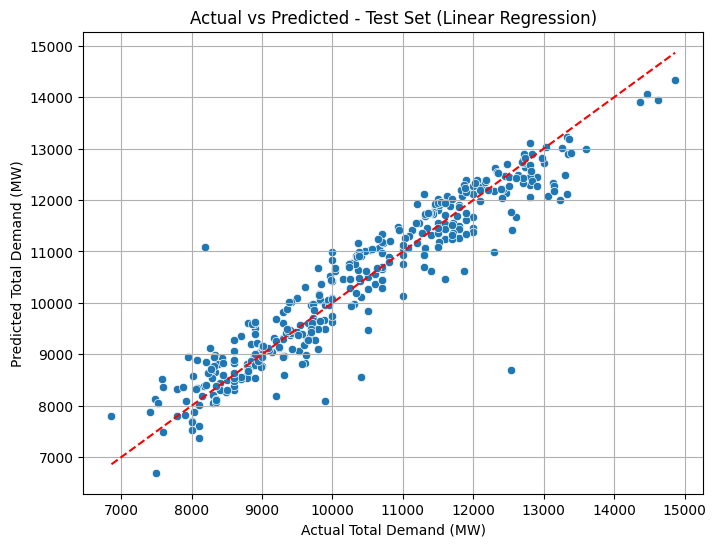

In [19]:
# Plot 2: Actual vs Predicted Scatter plot (Linear Regression Test Set)
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_lr_test_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Total Demand (MW)")
plt.ylabel("Predicted Total Demand (MW)")
plt.title("Actual vs Predicted - Test Set (Linear Regression)")
plt.grid(True)
plt.show()

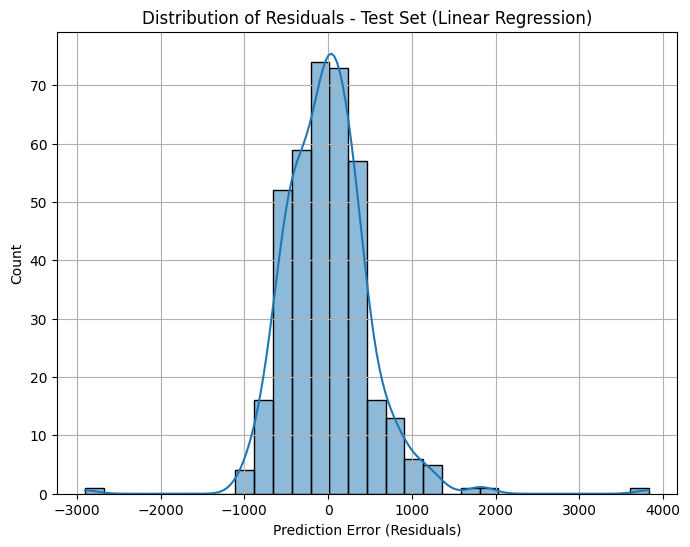

In [20]:
# Plot 3: Residuals Distribution
residuals = y_test - y_lr_test_pred
plt.figure(figsize=(8,6))
sns.histplot(residuals, kde=True, bins=30)
plt.xlabel("Prediction Error (Residuals)")
plt.title("Distribution of Residuals - Test Set (Linear Regression)")
plt.grid(True)
plt.show()

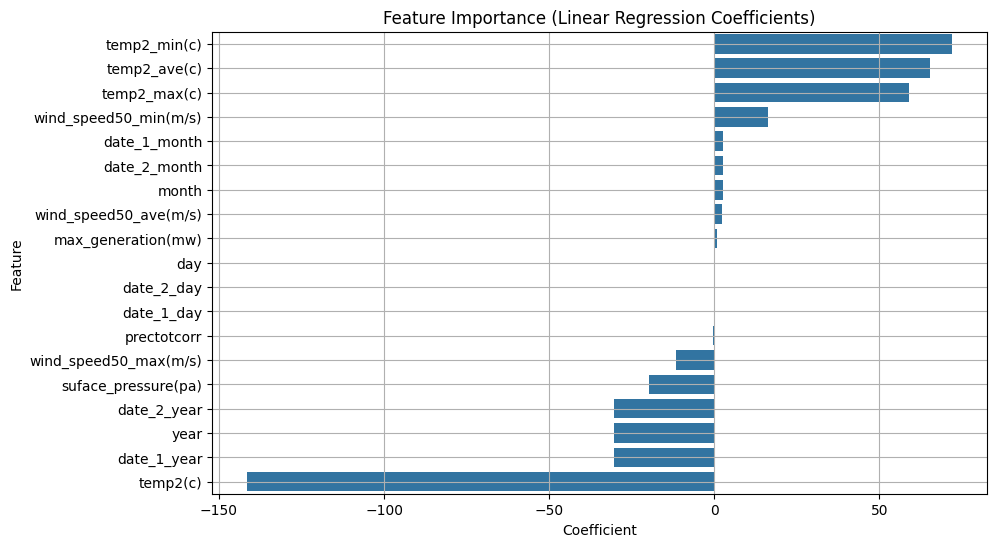

In [21]:
# Plot 4: Linear Regression Feature Coefficients
coeff_df = pd.DataFrame({
    'Feature': x.columns,
    'Coefficient': lr.coef_
}).sort_values(by='Coefficient', ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(data=coeff_df, x='Coefficient', y='Feature')
plt.title("Feature Importance (Linear Regression Coefficients)")
plt.grid(True)
plt.show()

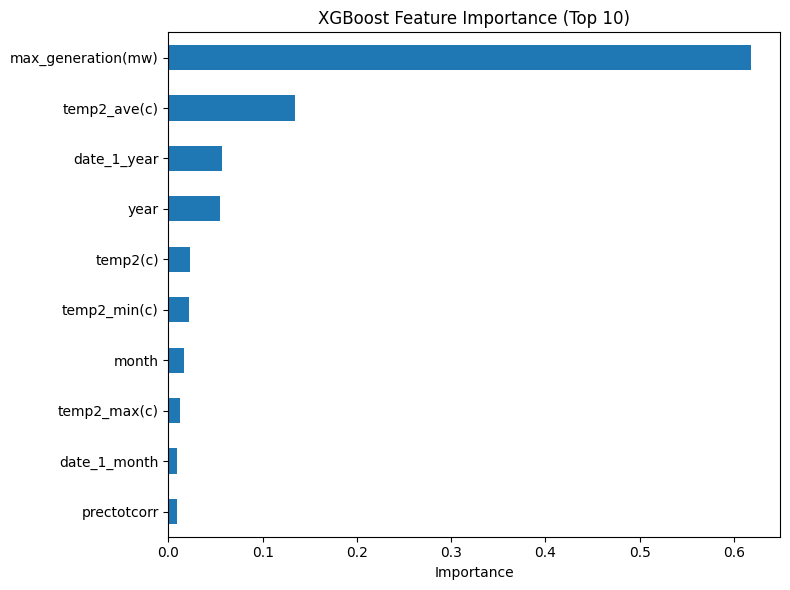

In [22]:
# Plot 5: XGBoost Feature Importance
importances = pd.Series(xgb.feature_importances_, index=x_train.columns).sort_values(ascending=False)
plt.figure(figsize=(8,6))
importances.head(10).plot(kind='barh')
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.title('XGBoost Feature Importance (Top 10)')
plt.tight_layout()
plt.show()